# Complete solutions and simulation

Notebook 2 calculated the second-order solution and the third-order terms needed for moments. We now obtain the **complete third-order solution**, including interactions among three distinct shock dates, and use it to simulate output, calculate generalized impulse responses, and see how fiscal multipliers vary along the simulated path.

Here we use a more automated workflow: `sequence_space/solution.py` assembles the calculations developed in the earlier notebooks, so a single solve supplies everything needed for simulation, moments, and GIRFs. After simulating, we'll also check the analytical moment formulas by numerically differentiating sample moments with respect to aggregate risk.

## 0. Setup

We use the same IKC model and calibration as notebook 2: a debt innovation finances a proportional tax cut, with debt decaying at $\rho_B=0.95$ and income adjusting to clear the asset market. As in the paper, we follow responses for $T=300$ quarters and include interactions between shocks less than $L=100$ quarters apart.

Government spending is fixed, so output and consumption changes coincide, $\Delta Y_t=\Delta C_t$. We use output for the GE results, with steady-state output normalized to one.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from smooth_sim.model import paper_household
from sequence_space.solution import solve_ge, solve_pe

plt.rcParams["figure.figsize"] = (7, 3.5)
T, L, rho_B = 300, 100, 0.95
sigma = 0.05
hh, ss = paper_household()

## 1. Obtain the complete solution

The call below obtains the first-, second-, and third-order output derivatives, together with the risky-steady-state and risk-transmission effects. The additional work relative to notebook 2 is calculating interactions among three distinct shock dates: these drop out of the moment formulas, but matter for a realized output path.

With four processes calculating the cubic history effects, the complete solve takes several minutes, including compilation and the lower-order calculations. Since the derivatives do not depend on $\sigma$, we only need to solve once.

In [ ]:
# workers=4 parallelizes the cubic history effect calculations across 4 processes
solution = solve_ge(hh, ss, T=T, L=L, rho_B=rho_B, order=3, workers=4)

## 2. Simulate output

We draw a single sequence of standard normal innovations $\bar\epsilon_t$ and write debt innovations as $\epsilon_t=\sigma\bar\epsilon_t$. The simulator returns $y_{1,t}$, $y_{2,t}$, and $y_{3,t}$, the coefficients of $\sigma$, $\sigma^2$, and $\sigma^3$ in output, including Taylor factors and anticipated-risk effects. For any value of $\sigma$, we can assemble them into
$$Y_t(\sigma)=Y_{ss}+\sigma y_{1,t}+\sigma^2y_{2,t}+\sigma^3y_{3,t}.$$

Simulating 100,000 quarters takes only a few seconds. We discard a burn-in of $T+L-2$ quarters to remove the effect of assuming zero shocks before the simulation starts. The plot shows the first 150 quarters and marks quarter 75 for the GIRF calculation below.

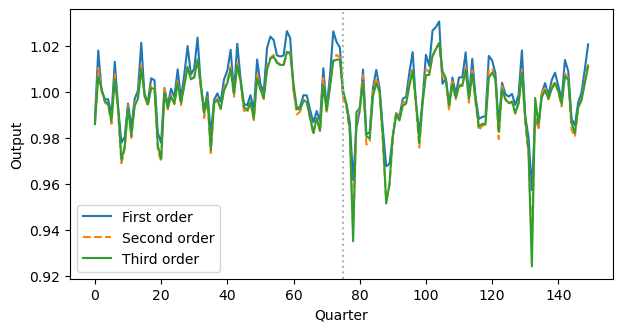

In [3]:
N, burnin = 100_000, T+L-2
epsbar = np.random.default_rng(20260930).standard_normal(N+burnin)
y1, y2, y3 = solution.simulate(epsbar, burnin=burnin)

Y_first = solution.X_ss+sigma*y1
Y_second = Y_first+sigma**2*y2
Y_third = Y_second+sigma**3*y3
plt.plot(Y_first[:150], label="First order")
plt.plot(Y_second[:150], "--", label="Second order")
plt.plot(Y_third[:150], label="Third order")
plt.axvline(75, color="0.7", linestyle=":")
plt.xlabel("Quarter"); plt.ylabel("Output")
plt.legend();

The downward shift from first to second order is much more visible than the difference between second and third order. The second-order path includes both the negative risky-steady-state shift from notebook 2 and the size and history effects of realized shocks. The third-order terms make smaller adjustments that depend on the particular shock history.

## 3. Check moments using the simulation

We first calculate the ergodic mean, variance, and first autocovariance using the analytical formulas from notebook 2. The mean correction is proportional to $\sigma^2$, and **Proposition 6** gives the covariance coefficients on $\sigma^2$ and $\sigma^4$.

In [4]:
mean = solution.ergodic_mean(sigma)
covariance = solution.covariances(sigma, lags=(0, 1))
print(f"Mean: {mean:.6f}")
print(f"Variance: {covariance[0]:.7f}")
print(f"First autocovariance: {covariance[1]:.7f}")

Mean: 0.995829
Variance: 0.0002285
First autocovariance: 0.0001250


To check these formulas, we Taylor-expand the sample moments in $\sigma$, using the same simulated paths at every value of $\sigma$. We compare their coefficients on $\sigma^2$ and $\sigma^4$ with the analytical ones.

The seven-point differentiation formulas below are exact for these polynomial sample moments apart from rounding error. We compare 25,000 and 100,000 quarters and check that halving or doubling the step size $h=0.02$ has negligible effect.

In [5]:
def sample_moments(s, n):
    Y = solution.X_ss+s*y1[:n]+s**2*y2[:n]+s**3*y3[:n]
    centered = Y-Y.mean()
    return np.array([Y.mean(), np.mean(centered**2),
                     np.mean(centered[1:]*centered[:-1])])

weights2 = np.array([2, -27, 270, -490, 270, -27, 2])/180
weights4 = np.array([-1, 12, -39, 56, -39, 12, -1])/6
h = 0.02

def sample_coefficients(h, n):
    values = np.array([sample_moments(s, n) for s in h*np.arange(-3, 4)])
    coeff2 = weights2 @ values/(2*h**2)
    coeff4 = weights4 @ values[:, 1:]/(24*h**4)
    return np.concatenate((coeff2, coeff4))

Sigma2, Sigma4 = solution.covariance_coefficients(lags=(0, 1))
reference = np.concatenate(([solution.mean_correction()], Sigma2, Sigma4))
short, full = sample_coefficients(h, 25_000), sample_coefficients(h, N)
labels = ["Mean: sigma^2", "Variance: sigma^2", "Autocovariance: sigma^2",
          "Variance: sigma^4", "Autocovariance: sigma^4"]
print(f"{'Coefficient':<25} {'Analytical':>12} {'25,000':>12} {'100,000':>12}")
for label, exact, a, b in zip(labels, reference, short, full):
    print(f"{label:<25} {exact:12.6f} {a:12.6f} {b:12.6f}")
step_error = max(np.max(abs(sample_coefficients(step, N)-full)) for step in (h/2, 2*h))
print(f"Largest change when halving or doubling h: {step_error:.2e}")

Coefficient                 Analytical       25,000      100,000
Mean: sigma^2                -1.668273    -1.666107    -1.668275
Variance: sigma^2             0.090537     0.090062     0.090868
Autocovariance: sigma^2       0.049295     0.048292     0.049436
Variance: sigma^4             0.349043     0.386987     0.399448
Autocovariance: sigma^4       0.279302     0.191312     0.274645
Largest change when halving or doubling h: 1.26e-12


The mean correction and leading covariances agree closely. The fourth-order coefficients are harder to estimate: even with 100,000 quarters, the variance coefficient is about 0.399, compared with 0.349 analytically, while the first-autocovariance coefficient is closer, at 0.275 versus 0.279. Changing the differentiation step has almost no effect, so the remaining discrepancies are consistent with sampling error. This is also a practical benefit of the analytical formulas: they give these coefficients without needing a long simulation.

## 4. A GIRF along the simulated path

Consider a new debt innovation of size $\nu=0.05$ at quarter 75. The GIRF is the revision in expected output after observing this innovation, relative to the forecast before observing it, as in **Proposition 5**. It averages over future innovations, rather than setting them to zero.

We pass the innovations preceding this date to `girf` and compare with the same innovation after a history of zeros. The response is independent of history at first order, but at higher orders it depends on the earlier shocks. The complete cubic solution includes interactions between the new innovation and two distinct past innovations.

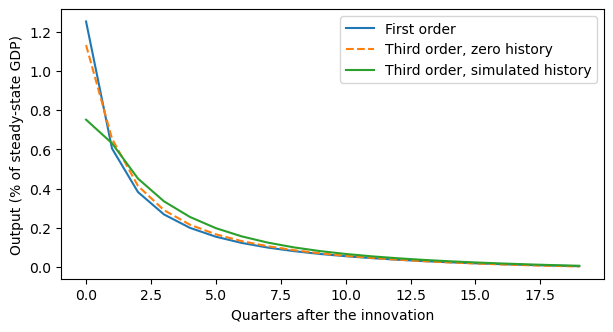

In [6]:
date, nu, horizon = 75, 0.05, 20
eps = sigma*epsbar[:burnin+date]
# Each returned GIRF includes all terms through its approximation order.
response = solution.girf(eps, nu, sigma, horizon=horizon)
zero_history = solution.girf(np.zeros_like(eps), nu, sigma, horizon=horizon)
plt.plot(100*response[0], label="First order")
plt.plot(100*zero_history[2], "--", label="Third order, zero history")
plt.plot(100*response[2], label="Third order, simulated history")
plt.xlabel("Quarters after the innovation"); plt.ylabel("Output (% of steady-state GDP)")
plt.legend();

The simulated history reduces the impact response by about a third relative to zero history, while slightly raising the response from quarter 2 onward. A GIRF also accounts for what was expected before the innovation: for instance, terms involving the square of the new innovation depend on $\nu^2-\sigma^2$, rather than $\nu^2$ alone. Here $\nu=\sigma$, so those terms vanish, and the difference between the two third-order curves comes from how earlier shocks change the transmission of the new tax cut.

## 5. Local multipliers along the simulated path

The GIRF shows how one particular history changes the response to a new shock. We can also look across many histories, plotting the marginal impact multiplier against output as in section 5 of the paper. Here we use our simpler IKC model, with only debt-financed tax-cut shocks, rather than the quantitative HANK model with several shocks.

At each date, we differentiate the third-order output solution with respect to an additional debt innovation, holding anticipated risk and the earlier shocks fixed. Using the paper's derivative notation for output,
$$\frac{\partial Y_t^{(3)}}{\partial\epsilon_t}
=Y_0+\sum_{l=0}^{L-1}Y_{0l}\epsilon_{t-l}
+\frac12\sum_{l,l'=0}^{L-1}Y_{0ll'}\epsilon_{t-l}\epsilon_{t-l'}
+\frac{\sigma^2}{2}Y_{\sigma\sigma0}.$$
The sums include today's realized shock ($l=0$): we are asking what a marginal *additional* tax cut would do at each point in the simulation. We differentiate with respect to $\epsilon_t=\sigma\bar\epsilon_t$ to measure output per unit of tax cut, whereas differentiating with respect to $\bar\epsilon_t$ would introduce an extra factor of $\sigma$.

The stored arrays give $Y_{0l}$ and $Y_{0ll'}$ in `X2[0]` and `X3[0]`, while `X_rss[0] + X_tvp[0]` gives $Y_{\sigma\sigma0}$. We use these to calculate multipliers for the first 1,000 quarters of the simulation.

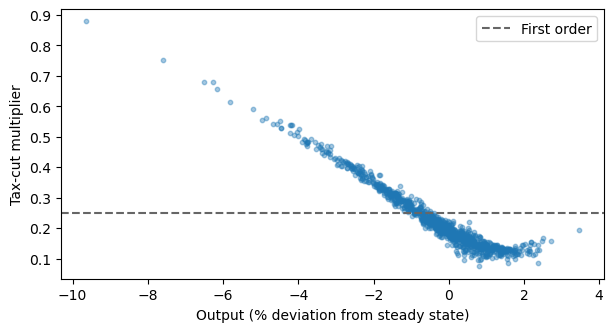

In [7]:
Y1, Y2, Y3 = solution.X1, solution.X2, solution.X3
Y_sigma_sigma = solution.X_rss+solution.X_tvp
multiplier = np.empty(1_000)
for t in range(len(multiplier)):
    # e[l] is the realized innovation l quarters before this date, including l=0.
    e = sigma*epsbar[burnin+t-L+1:burnin+t+1][::-1]
    multiplier[t] = Y1[0]+Y2[0] @ e+(e @ Y3[0] @ e+sigma**2*Y_sigma_sigma[0])/2

plt.scatter(100*(Y_third[:len(multiplier)]/solution.X_ss-1), multiplier, s=10, alpha=0.4)
plt.axhline(Y1[0], color="0.4", linestyle="--", label="First order")
plt.xlabel("Output (% deviation from steady state)"); plt.ylabel("Tax-cut multiplier")
plt.legend();

The multiplier generally falls as output rises, but the relationship flattens at higher output. When output is about 5% below its deterministic steady state, the multiplier is around 0.6, compared with the constant first-order value of 0.25. This is consistent with the earlier size and history effects: after positive income shocks, households spend less of an additional tax cut on impact. The nonlinearity is more pronounced in these local multipliers than in output itself, since the response to a finite shock integrates over marginal effects that can vary substantially with shock size.

Different histories can produce similar output but different multipliers, so the points do not all lie on one curve. A few points out of the 1000 at high output even suggest an increasing multiplier. With the rather large fiscal shock volatility $\sigma=0.05$ here, these may reflect limits of the third-order approximation far from the steady state.

## Other uses of the solution routines

We can also solve at first or second order by setting `order=1` or `order=2`, or use a single process with `workers=1`. If we only want moments, `only_moments=True` avoids calculating effects we do not need. At second order, this means calculating just the size effects and anticipated risk needed for the mean. At third order, we also get the effects needed for covariances, but skip cubic interactions among three distinct shock dates.

For partial equilibrium, we can use `solve_pe(hh, ss, T=T, L=L, rho_Z=0.)`, where `rho_Z` controls the persistence of aggregate income. This holds interest rates and transfers fixed and gives us consumption rather than output. We can then simulate paths, calculate moments, and obtain GIRFs in the same way as above.